In [1]:
import anndata as ad
import numpy as np
from sklearn.neighbors import NearestNeighbors
import os,sys,re
import matplotlib.pyplot as plt
import scanpy as sc

/home/jwinchel/miniconda3/envs/heimdall/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_csv from `anndata` is deprecated. Import anndata.io.read_csv instead.
  warnings.warn(msg, FutureWarning)
/home/jwinchel/miniconda3/envs/heimdall/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_excel from `anndata` is deprecated. Import anndata.io.read_excel instead.
  warnings.warn(msg, FutureWarning)
/home/jwinchel/miniconda3/envs/heimdall/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_hdf from `anndata` is deprecated. Import anndata.io.read_hdf instead.
  warnings.warn(msg, FutureWarning)
/home/jwinchel/miniconda3/envs/heimdall/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_loom from `anndata` is deprecated. Import anndata.io.read_loom instead.
  warnings.warn(msg, FutureWarning)
/home/jwinchel/miniconda3/envs/heimdall/lib/python3.10/site-packages/anndata/utils.py:

In [2]:
import numpy as np
from sklearn.neighbors import NearestNeighbors

def add_top_st_matches_with_coords(
    sc_data,
    st_data,
    embedding_key="X_pca_harmony",
    spatial_cols=("CenterX_global_px", "CenterY_global_px"),
    n_matches=3,
):
    """
    For each scRNA-seq cell:
      - find top n nearest ST cells in Harmony space
      - store their IDs, distances, and spatial coordinates (x, y)

    Adds to sc_data.obs:
      st_match_{i}_id
      st_match_{i}_dist
      st_match_{i}_x
      st_match_{i}_y
    """

    if embedding_key not in sc_data.obsm:
        raise KeyError(f"{embedding_key} not found in sc_data.obsm")
    if embedding_key not in st_data.obsm:
        raise KeyError(f"{embedding_key} not found in st_data.obsm")

    xcol, ycol = spatial_cols
    for col in spatial_cols:
        if col not in st_data.obs:
            raise KeyError(f"{col} not found in st_data.obs")

    # embeddings
    sc_emb = np.asarray(sc_data.obsm[embedding_key])
    st_emb = np.asarray(st_data.obsm[embedding_key])

    # nearest neighbors in embedding space
    nn = NearestNeighbors(n_neighbors=n_matches, metric="euclidean")
    nn.fit(st_emb)

    distances, indices = nn.kneighbors(sc_emb)

    # IDs and coordinates
    st_ids = st_data.obs_names.to_numpy()
    st_coords = st_data.obs[[xcol, ycol]].to_numpy()

    # assign to sc_data.obs
    for j in range(n_matches):
        sc_data.obs[f"st_match_{j+1}_id"] = st_ids[indices[:, j]].astype(str)
        sc_data.obs[f"st_match_{j+1}_dist"] = distances[:, j]
        sc_data.obs[f"st_match_{j+1}_x"] = st_coords[indices[:, j], 0]
        sc_data.obs[f"st_match_{j+1}_y"] = st_coords[indices[:, j], 1]

    return sc_data

In [ ]:
SC_FILE = "/work/magroup/skrieger/Syndri/data/label_transfer/SC_NSCLC_labeltransfer_consolidated.h5ad"
ST_DIR = "/compute/oven-0-13/jwinchel/spatial_adata/"
ST_FILES = sorted([os.path.join(ST_DIR,f) for f in os.listdir(ST_DIR) if f.endswith('annotated.h5ad')])
print(ST_FILES)

# read single-cell
sc_data_orig = ad.read_h5ad(SC_FILE)
sc_data_orig = sc_data_orig[sc_data_orig.obs['Tissue'] == 'tumor',:].copy()
# sc_data.obs = sc_data.obs.reset_index(drop=True)
sc_data_orig.obs['batch'] = 'sc'

for i,ST_FILE in enumerate(ST_FILES):
    # read st
    st_data = ad.read_h5ad(ST_FILE)
    st_data.obs['batch'] = 'st'
    
    # make a copy of sc
    sc_data = sc_data_orig.copy()

    # harmony integrate in pca space
    adata = sc_data.concatenate(st_data, batch_key='batch', batch_categories=['sc','st'])

    # normalize and get PCA
    sc.pp.normalize_total(adata)
    sc.pp.log1p(adata)
    sc.pp.scale(adata)
    sc.tl.pca(adata, n_comps=30)

    print(adata.obs.columns.tolist())
    print(adata.obs["batch"].dtype)
    print(adata.obs["batch"].value_counts(dropna=False))
    print(adata.obsm["X_pca"].shape)
    # integrate sc and st via harmony
    sc.external.pp.harmony_integrate(adata, 'batch', basis='X_pca')

    is_st = adata.obs['batch'] == 'st'
    is_sc = adata.obs['batch'] == 'sc'

    # subset integrated embeddings
    sc_data.obsm['X_pca_harmony'] = adata.obsm['X_pca_harmony'][is_sc,:]
    st_data.obsm['X_pca_harmony'] = adata.obsm['X_pca_harmony'][is_st,:]
    
    # get top matches
    sc_data = add_top_st_matches_with_coords(
        sc_data,
        st_data,
        embedding_key="X_pca_harmony",
        spatial_cols=("CenterX_global_px", "CenterY_global_px"),
        n_matches=10,
    )
    
    # get mapping with penalized reusage
    dist_cols = sorted([c for c in sc_data.obs.columns if c.startswith("st_match_") and c.endswith("_dist")])
    id_cols = sorted([c for c in sc_data.obs.columns if c.startswith("st_match_") and c.endswith("_id")])
    d = sc_data.obs[dist_cols].to_numpy()

    tau = np.median(d)

    # convert distance to weights (similarity ~ exp(-distance^2 / tau^2)), tau coresponds to falloff
    w = np.exp(-(d**2) / (tau**2 + 1e-8))
    w = w / w.sum(axis=1, keepdims=True)


    counts = sc_data.obs["st_match_1_id"].value_counts().to_dict()

    # for each sc cell, penalize weights
    for i in range(sc_data.n_obs):
        ids = [sc_data.obs.iloc[i][col] for col in id_cols]
        
        penalties = np.array([1.0 / (counts.get(x, 1) + 1e-6) for x in ids])
        w[i] = w[i] * penalties
        w[i] = w[i] / w[i].sum()


    k = w.shape[1]
    st_choices = np.arange(k)
    selected_idx = np.array([
        np.random.choice(st_choices, p=w[i])
        for i in range(w.shape[0])
    ])


    st_ids = sc_data.obs[id_cols].to_numpy()

    selected_st_ids = st_ids[np.arange(len(st_ids)), selected_idx]

    sc_data.obs["sampled_st_id"] = selected_st_ids
    x_cols = [ f"st_match_{j+1}_x" for j in selected_idx]
    y_cols = [ f"st_match_{j+1}_y" for j in selected_idx]
    sc_data.obs["sampled_st_x"] = [sc_data.obs.iloc[i][x_cols[i]] for i in range(len(x_cols))]
    sc_data.obs["sampled_st_y"] = [sc_data.obs.iloc[i][y_cols[i]] for i in range(len(y_cols))]

    print(sc_data.obs['sampled_st_id'].value_counts().shape[0] / st_data.n_obs)



['/compute/oven-0-13/jwinchel/spatial_adata/cosmx_nsclc_Lung12_adata_annotated.h5ad', '/compute/oven-0-13/jwinchel/spatial_adata/cosmx_nsclc_Lung13_adata_annotated.h5ad', '/compute/oven-0-13/jwinchel/spatial_adata/cosmx_nsclc_Lung5-Rep1_adata_annotated.h5ad', '/compute/oven-0-13/jwinchel/spatial_adata/cosmx_nsclc_Lung5-Rep2_adata_annotated.h5ad', '/compute/oven-0-13/jwinchel/spatial_adata/cosmx_nsclc_Lung5-Rep3_adata_annotated.h5ad', '/compute/oven-0-13/jwinchel/spatial_adata/cosmx_nsclc_Lung6_adata_annotated.h5ad', '/compute/oven-0-13/jwinchel/spatial_adata/cosmx_nsclc_Lung9-Rep1_adata_annotated.h5ad', '/compute/oven-0-13/jwinchel/spatial_adata/cosmx_nsclc_Lung9-Rep2_adata_annotated.h5ad']


/tmp/ipykernel_121790/316833032.py:21: FutureWarning: Use anndata.concat instead of AnnData.concatenate, AnnData.concatenate is deprecated and will be removed in the future. See the tutorial for concat at: https://anndata.readthedocs.io/en/latest/concatenation.html
  adata = sc_data.concatenate(st_data, batch_key='batch', batch_categories=['sc','st'])
/home/jwinchel/miniconda3/envs/heimdall/lib/python3.10/site-packages/scanpy/preprocessing/_normalization.py:233: UserWarning: Some cells have zero counts
  warn(UserWarning("Some cells have zero counts"))
2026-04-07 13:04:54,658 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...


['species', 'filename', 'sample', 'GSM_ID', 'cell_ID', 'Patient', 'Tissue', 'Barcoding emulsion', 'Library', 'Total counts', 'Percent counts from mitochondrial genes', 'Most likely LM22 cell type', 'Major cell type', 'Minor subset', 'used_in_NSCLC_all_cells', 'used_in_NSCLC_and_blood_immune', 'used_in_NSCLC_immune', 'used_in_NSCLC_non_immune', 'used_in_blood', 'Barcode', 'batch', 'cell_type', 'fov', 'tissue', 'CenterX_local_px', 'CenterY_local_px', 'CenterX_global_px', 'CenterY_global_px', 'sdimx', 'sdimy', 'cell_ID_long', 'Area', 'AspectRatio', 'Width', 'Height', 'Mean.CD298', 'Max.CD298', 'Mean.G', 'Max.G', 'Mean.Y', 'Max.Y', 'Mean.R', 'Max.R', 'Mean.DAPI', 'Max.DAPI', 'dualfiles', 'Slide_name', 'Run_name', 'ISH.concentration', 'Dash', 'slide_ID_numeric', 'Run_Tissue_name', 'Panel', 'Diversity', 'totalcounts', 'log10totalcounts', 'background', 'remove_flagged_cells', 'patient', 'cell_type_orig', 'niche', 'prop_tumor_in_100_neighbors']
category
batch
st    74025
sc    40362
Name: coun

2026-04-07 13:05:00,149 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-04-07 13:05:00,381 - harmonypy - INFO - Iteration 1 of 10
2026-04-07 13:05:23,269 - harmonypy - INFO - Iteration 2 of 10
2026-04-07 13:05:45,917 - harmonypy - INFO - Converged after 2 iterations


0.13657548125633232


In [8]:
st_data.obs['cell_type'].value_counts()

cell_type
tumor 12        18267
neutrophil      16699
fibroblast      16548
plasmablast      5045
endothelial      3121
nan              2721
T CD4 naive      2247
epithelial       2154
B-cell           1356
T CD8 naive      1294
macrophage       1291
mast             1076
mDC               780
NK                567
pDC               408
monocyte          143
tumor 5           134
tumor 9            80
T CD4 memory       29
tumor 6            26
Treg               18
T CD8 memory       16
tumor 13            5
Name: count, dtype: int64

In [ ]:
# read st
st_data = ad.read_h5ad(ST_FILE)
st_data.obs['batch'] = 'st'

# harmony integrate in pca space
adata = sc_data.concatenate(st_data, batch_key='batch', batch_categories=['sc','st'])

# find 10 nearest neighbors in harmony space for each st cell

# use equivalent ST cell for synthetic neighbor transcript sampling


# normalize and get PCA
sc.pp.normalize_total(adata)
sc.pp.log1p(adata)
sc.pp.scale(adata)
sc.tl.pca(adata, n_comps=30)

print(adata.obs.columns.tolist())
print(adata.obs["batch"].dtype)
print(adata.obs["batch"].value_counts(dropna=False))
print(adata.obsm["X_pca"].shape)
# integrate sc and st via harmony
sc.external.pp.harmony_integrate(adata, 'batch', basis='X_pca')

is_st = adata.obs['batch'] == 'st'
is_sc = adata.obs['batch'] == 'sc'

# subset integrated embeddings
sc_data.obsm['X_pca_harmony'] = adata.obsm['X_pca_harmony'][is_sc,:]
st_data.obsm['X_pca_harmony'] = adata.obsm['X_pca_harmony'][is_st,:]

/tmp/ipykernel_2307885/2514698894.py:12: FutureWarning: Use anndata.concat instead of AnnData.concatenate, AnnData.concatenate is deprecated and will be removed in the future. See the tutorial for concat at: https://anndata.readthedocs.io/en/latest/concatenation.html
  adata = sc_data.concatenate(st_data, batch_key='batch', batch_categories=['sc','st'])


['species', 'filename', 'sample', 'GSM_ID', 'cell_ID', 'Patient', 'Tissue', 'Barcoding emulsion', 'Library', 'Total counts', 'Percent counts from mitochondrial genes', 'Most likely LM22 cell type', 'Major cell type', 'Minor subset', 'used_in_NSCLC_all_cells', 'used_in_NSCLC_and_blood_immune', 'used_in_NSCLC_immune', 'used_in_NSCLC_non_immune', 'used_in_blood', 'Barcode', 'batch', 'cell_type', 'fov', 'tissue', 'sdimx', 'sdimy', 'Area', 'AspectRatio', 'Width', 'Height', 'Mean.CD298', 'Max.CD298', 'Mean.G', 'Max.G', 'Mean.Y', 'Max.Y', 'Mean.R', 'Max.R', 'Mean.DAPI', 'Max.DAPI', 'dualfiles', 'Slide_name', 'Run_name', 'ISH.concentration', 'Dash', 'slide_ID_numeric', 'Run_Tissue_name', 'Panel', 'Diversity', 'totalcounts', 'log10totalcounts', 'background', 'remove_flagged_cells', 'patient', 'niche', 'prop_tumor_in_100_neighbors', 'cell_ID_short', 'CenterX_local_px', 'CenterY_local_px', 'CenterX_global_px', 'CenterY_global_px', 'split', 'ADM_ID_0', 'ADM_ID_1', 'ADM_ID_2']
category
batch
st    

2026-03-24 11:53:52,274 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-03-24 11:53:58,785 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-03-24 11:53:59,127 - harmonypy - INFO - Iteration 1 of 10
2026-03-24 11:54:32,056 - harmonypy - INFO - Iteration 2 of 10
2026-03-24 11:55:01,022 - harmonypy - INFO - Iteration 3 of 10
2026-03-24 11:55:30,786 - harmonypy - INFO - Iteration 4 of 10
2026-03-24 11:55:59,968 - harmonypy - INFO - Iteration 5 of 10
2026-03-24 11:56:20,829 - harmonypy - INFO - Iteration 6 of 10
2026-03-24 11:56:38,852 - harmonypy - INFO - Iteration 7 of 10
2026-03-24 11:56:55,487 - harmonypy - INFO - Iteration 8 of 10
2026-03-24 11:57:08,059 - harmonypy - INFO - Iteration 9 of 10
2026-03-24 11:57:20,524 - harmonypy - INFO - Converged after 9 iterations


In [6]:
is_st = adata.obs['batch'] == 'st'
is_sc = adata.obs['batch'] == 'sc'

sc_data.obsm['X_pca_harmony'] = adata.obsm['X_pca_harmony'][is_sc.to_numpy(), :]
st_data.obsm['X_pca_harmony'] = adata.obsm['X_pca_harmony'][is_st.to_numpy(), :]

In [7]:
sc_data = add_top_st_matches_with_coords(
    sc_data,
    st_data,
    embedding_key="X_pca_harmony",
    spatial_cols=("CenterX_global_px", "CenterY_global_px"),
    n_matches=10,
)

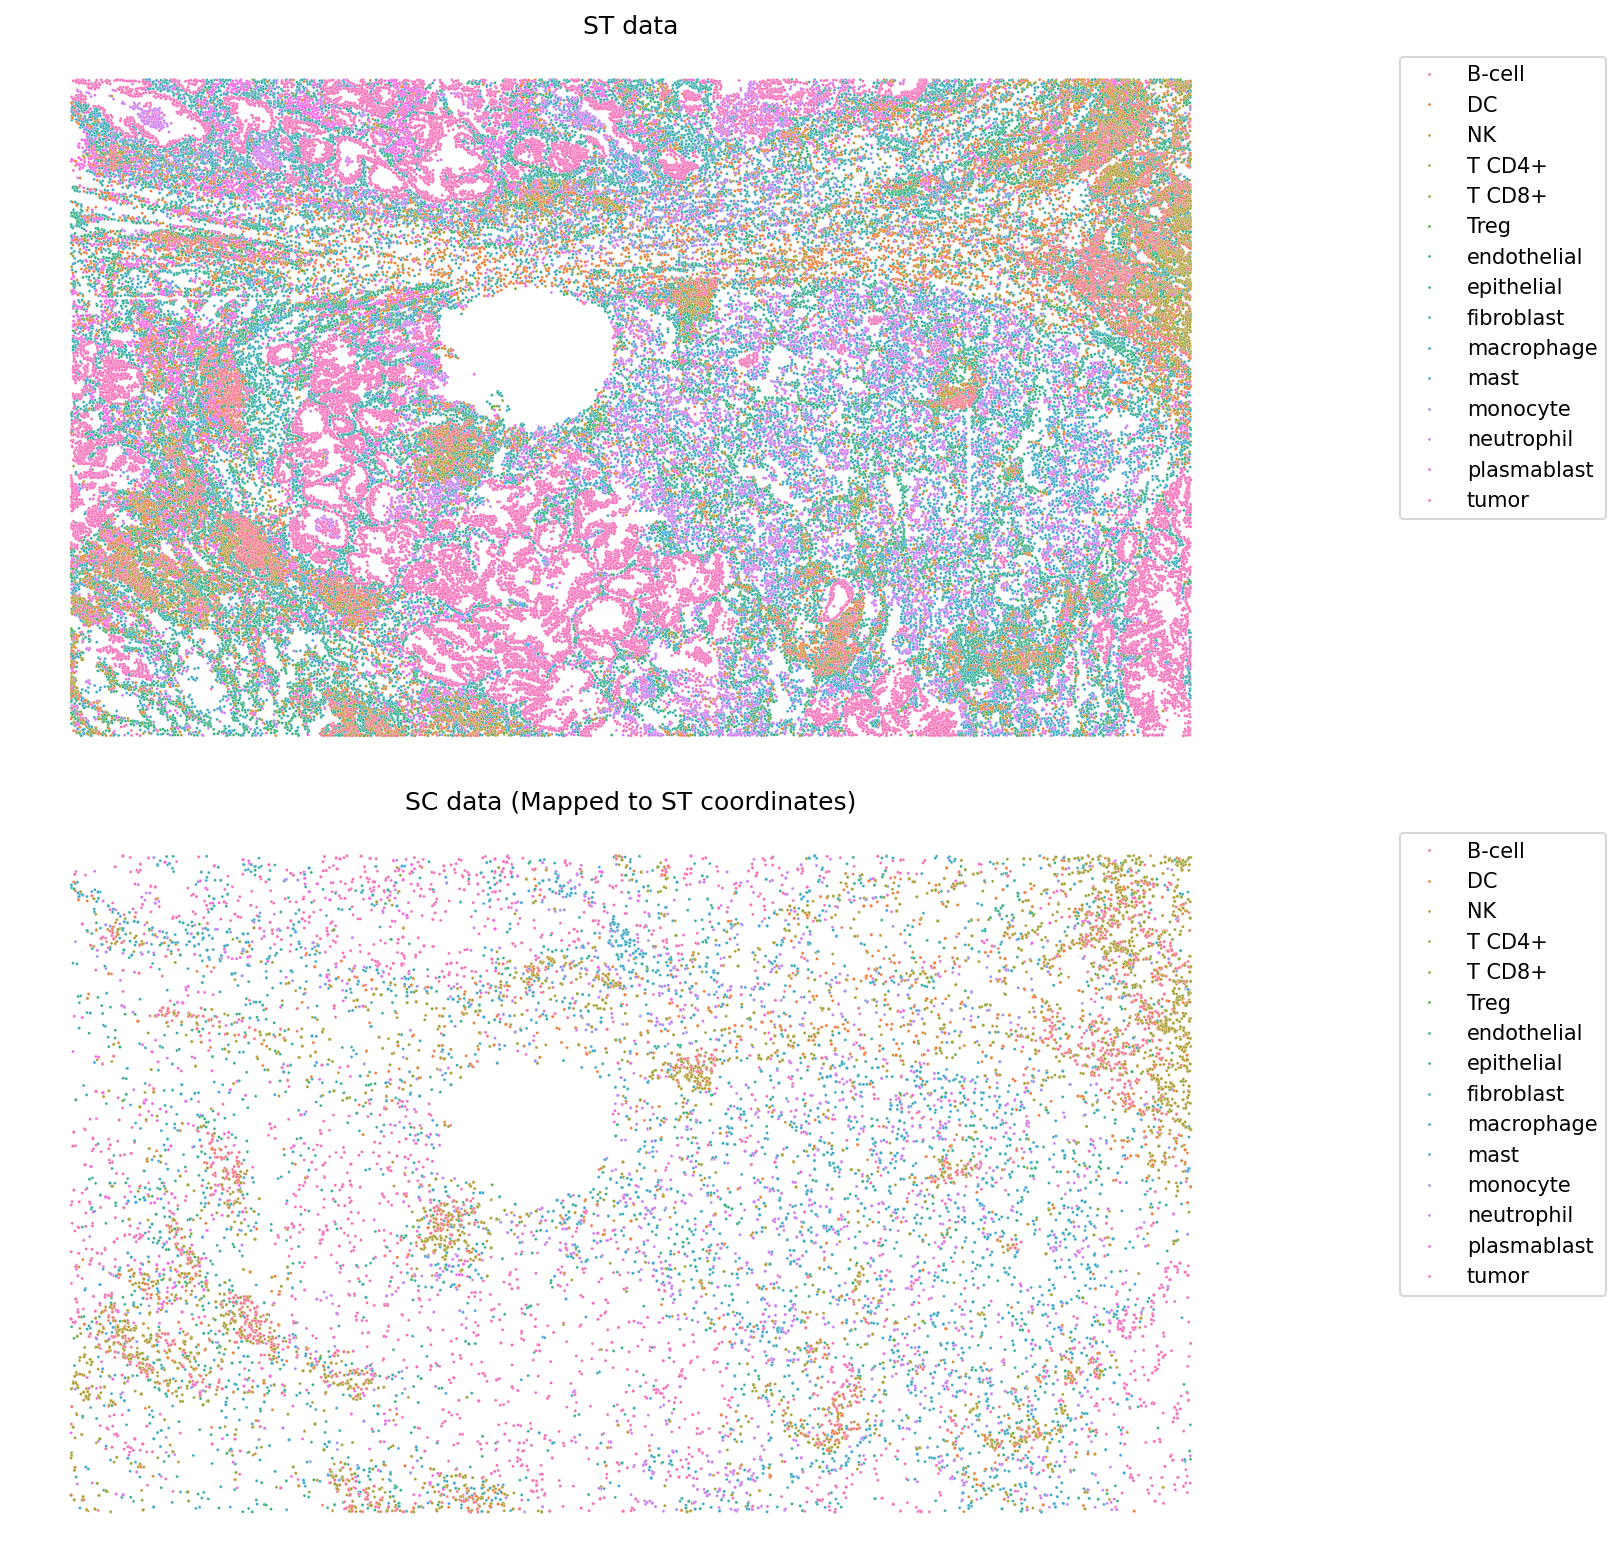

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt
fig,axes = plt.subplots(nrows =2, ncols=1, figsize=(11,10.5),dpi=150)



sns.scatterplot(st_data.obs, x="CenterX_global_px", y="CenterY_global_px", hue='cell_type',s=2,ax=axes[0] )
axes[0].axis('off')
axes[0].legend(loc='upper right', bbox_to_anchor=(1.3, 1))
axes[0].set_title("ST data")
sns.scatterplot(sc_data.obs, x='st_match_1_x', y='st_match_1_y', hue='cell_type',s=2,ax=axes[1])
axes[1].axis('off')
axes[1].legend(loc='upper right', bbox_to_anchor=(1.3, 1))
axes[1].set_title("SC data (Mapped to ST coordinates)")
fig.tight_layout()

In [9]:
map_counts = sc_data.obs['st_match_1_id'].value_counts().reset_index(name='map_count').sort_values('map_count', ascending=False)
map_counts

map_counts.shape[0] / st_data.n_obs

0.12943613395644987

In [10]:
map_counts.head(20)

,st_match_1_id,map_count
0,31523,333
1,31143,189
2,20234,129
3,83890,124
4,39423,123
5,67200,118
6,38047,109
7,67959,104
8,84062,100
9,16259,97


In [11]:
sc_data.obs['Tissue'].value_counts()

Tissue
tumor    40362
Name: count, dtype: int64

In [ ]:
dist_cols = sorted([c for c in sc_data.obs.columns if c.startswith("st_match_") and c.endswith("_dist")])
id_cols = sorted([c for c in sc_data.obs.columns if c.startswith("st_match_") and c.endswith("_id")])
d = sc_data.obs[dist_cols].to_numpy()

tau = np.median(d)

# convert distance to weights (similarity ~ exp(-distance^2 / tau^2)), tau coresponds to falloff
w = np.exp(-(d**2) / (tau**2 + 1e-8))
w = w / w.sum(axis=1, keepdims=True)


counts = sc_data.obs["st_match_1_id"].value_counts().to_dict()

# for each sc cell, penalize weights
for i in range(sc_data.n_obs):
    ids = [sc_data.obs.iloc[i][col] for col in id_cols]
    
    penalties = np.array([1.0 / (counts.get(x, 1) + 1e-6) for x in ids])
    w[i] = w[i] * penalties
    w[i] = w[i] / w[i].sum()


k = w.shape[1]
st_choices = np.arange(k)
selected_idx = np.array([
    np.random.choice(st_choices, p=w[i])
    for i in range(w.shape[0])
])


st_ids = sc_data.obs[id_cols].to_numpy()

selected_st_ids = st_ids[np.arange(len(st_ids)), selected_idx]

sc_data.obs["sampled_st_id"] = selected_st_ids
x_cols = [ f"st_match_{j+1}_x" for j in selected_idx]
y_cols = [ f"st_match_{j+1}_y" for j in selected_idx]
sc_data.obs["sampled_st_x"] = [sc_data.obs.iloc[i][x_cols[i]] for i in range(len(x_cols))]
sc_data.obs["sampled_st_y"] = [sc_data.obs.iloc[i][y_cols[i]] for i in range(len(y_cols))]
sc_data.obs

In [14]:
sc_data.obs['sampled_st_id'].value_counts().shape[0] / st_data.n_obs

0.18486357421277116

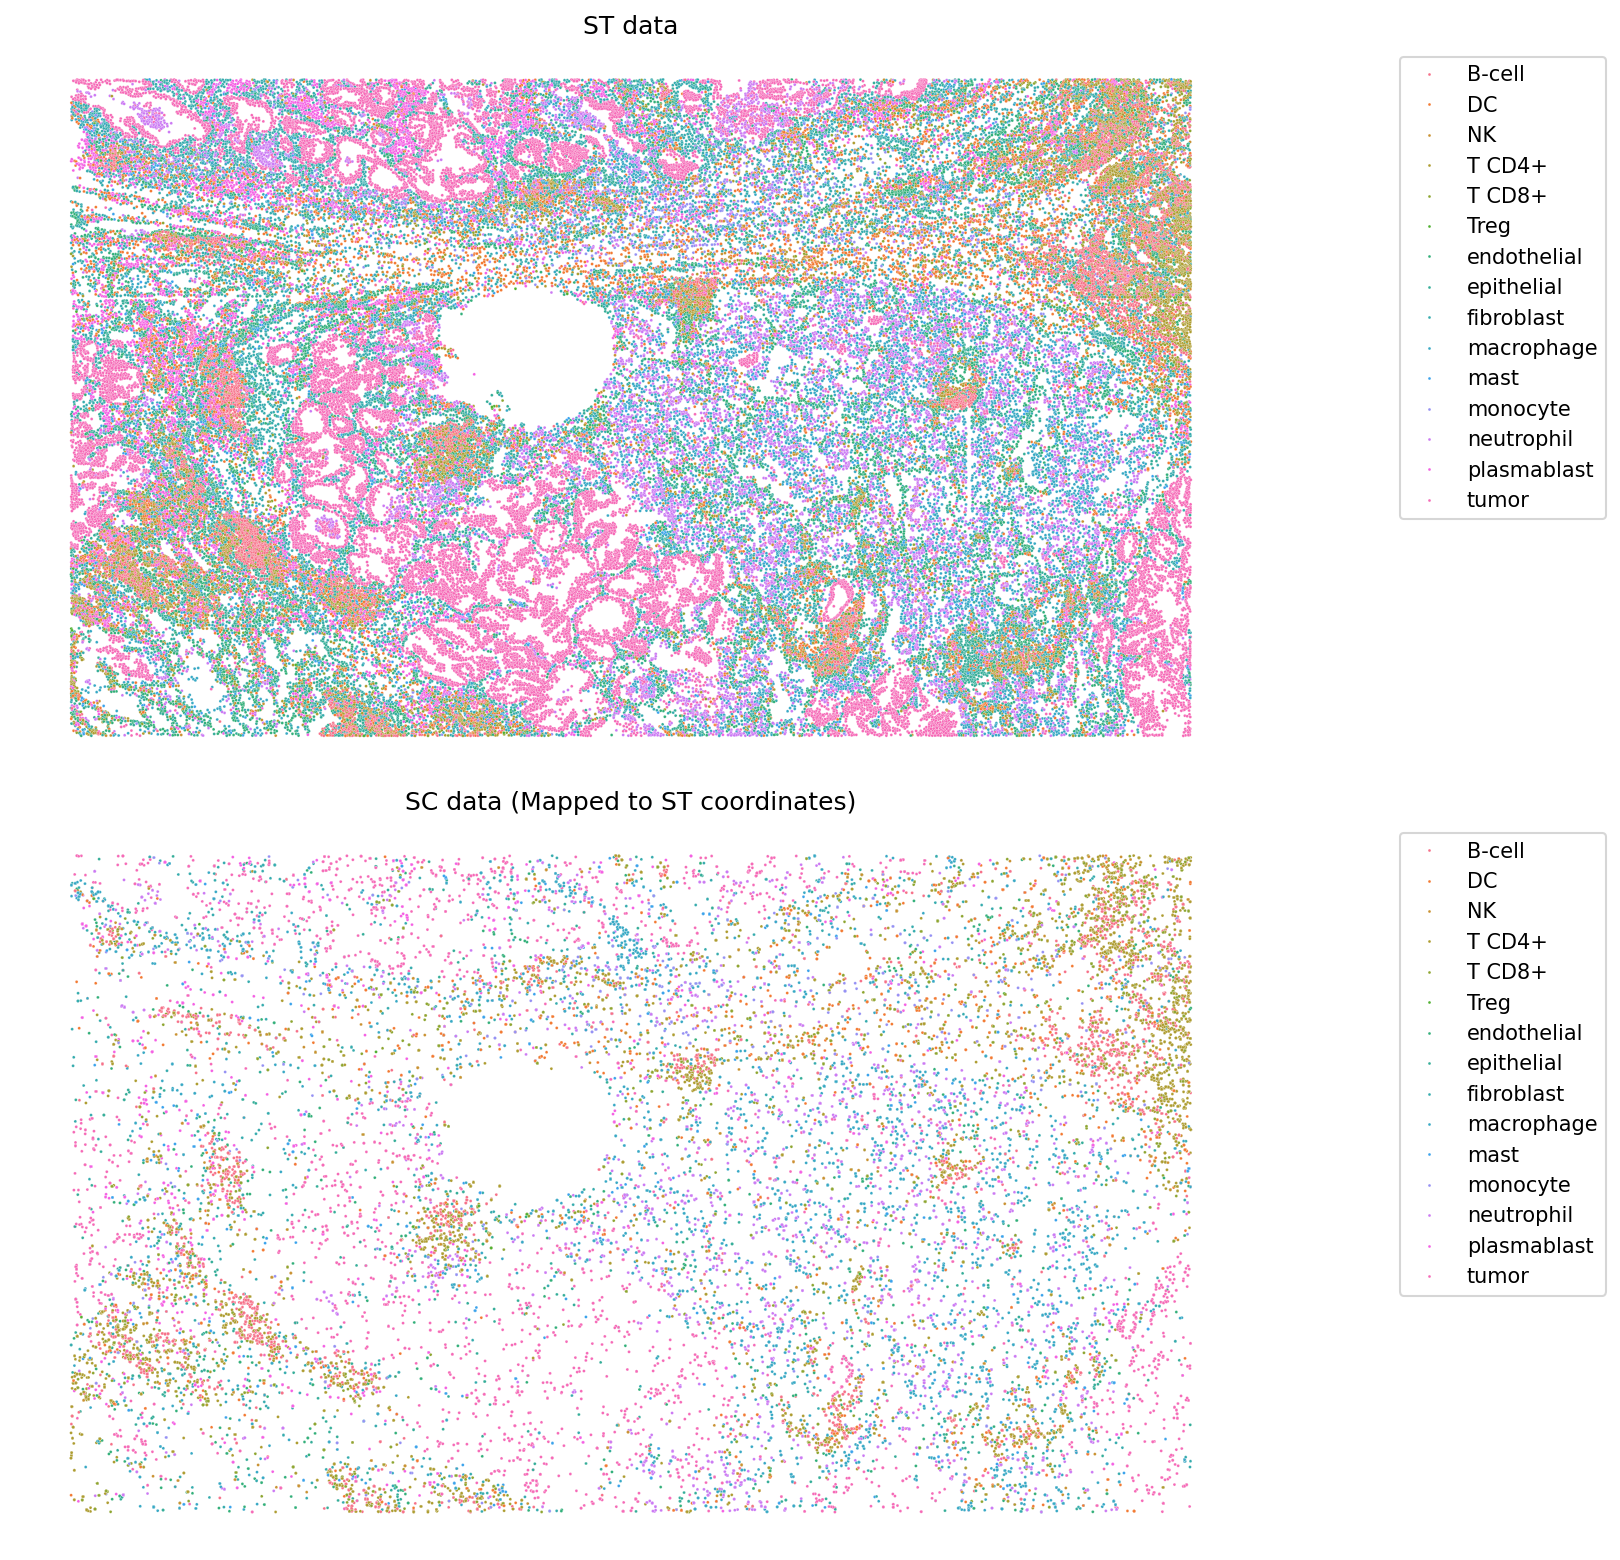

In [43]:
import seaborn as sns
import matplotlib.pyplot as plt
fig,axes = plt.subplots(nrows =2, ncols=1, figsize=(11,10.5),dpi=150)



sns.scatterplot(st_data.obs, x="CenterX_global_px", y="CenterY_global_px", hue='cell_type',s=2,ax=axes[0] )
axes[0].axis('off')
axes[0].legend(loc='upper right', bbox_to_anchor=(1.3, 1))
axes[0].set_title("ST data")
sns.scatterplot(sc_data.obs, x='sampled_st_x', y='sampled_st_y', hue='cell_type',s=2,ax=axes[1])
axes[1].axis('off')
axes[1].legend(loc='upper right', bbox_to_anchor=(1.3, 1))
axes[1].set_title("SC data (Mapped to ST coordinates)")
fig.tight_layout()

In [27]:
import numpy as np
import pandas as pd

from admix_scores import estimate_cell_adjacency, estimate_cell_type_adjacency


# ----------------------------
# 1) Build a cell-level dataframe from st_data
#    Assumes coordinates are global
# ----------------------------
def build_cell_df_from_st_data(
    st_data,
    *,
    cell_type_col="cell_type",
    # Choose ONE of these coordinate sources:
    x_col=None,      # e.g. "CenterX_global_px" or "x_global_px"
    y_col=None,      # e.g. "CenterY_global_px" or "y_global_px"
    obsm_key="spatial",  # fallback if x_col/y_col not present
    # optional unit conversion
    px_to_um=None,   # e.g. 0.18 if 180 nm per pixel
):
    obs = st_data.obs.copy()

    if cell_type_col not in obs.columns:
        raise KeyError(f"{cell_type_col!r} not found in st_data.obs")

    # cell ids
    obs["cell"] = st_data.obs_names.astype(str)

    # coordinates
    if x_col is not None and y_col is not None:
        if x_col not in obs.columns or y_col not in obs.columns:
            raise KeyError(f"x_col/y_col not found in obs: {x_col}, {y_col}")
        obs["x"] = obs[x_col].astype(float)
        obs["y"] = obs[y_col].astype(float)
    else:
        if obsm_key not in st_data.obsm:
            raise KeyError(
                f"Neither x_col/y_col provided nor st_data.obsm[{obsm_key!r}] found."
            )
        xy = np.asarray(st_data.obsm[obsm_key])
        if xy.ndim != 2 or xy.shape[1] != 2:
            raise ValueError(f"st_data.obsm[{obsm_key!r}] must be (n, 2), got {xy.shape}")
        obs["x"] = xy[:, 0].astype(float)
        obs["y"] = xy[:, 1].astype(float)

    # optional unit conversion
    if px_to_um is not None:
        obs["x"] *= float(px_to_um)
        obs["y"] *= float(px_to_um)

    # keep only required columns
    cell_df = obs[["x", "y", cell_type_col, "cell"]].rename(
        columns={cell_type_col: "cell_type"}
    )

    # drop missing values
    cell_df = cell_df.dropna(subset=["x", "y", "cell", "cell_type"]).reset_index(drop=True)
    return cell_df


# Example
cell_df = build_cell_df_from_st_data(
    st_data,
    cell_type_col="cell_type",
    x_col="CenterX_global_px",
    y_col="CenterY_global_px",
    obsm_key="spatial",
    px_to_um=None,   # set to 0.18 if needed
)

# Optional label collapsing
cell_df["cell_type"] = cell_df["cell_type"].replace({
    "T CD4 naive": "T CD4+",
    "T CD4 memory": "T CD4+",
    "T CD8 naive": "T CD8+",
    "T CD8 memory": "T CD8+",
    "pDC": "DC",
    "mDC": "DC",
}).astype(str)

cell_df.loc[
    cell_df["cell_type"].astype(str).str.startswith("tumor"),
    "cell_type"
] = "tumor"


# ----------------------------
# 2) Compute one global cell adjacency graph
# ----------------------------
edge_kwargs = dict(
    random_shift=1e-3,
    edge_max_mad=4.0,
    n_jobs=1,
)

if cell_df["cell"].nunique() < 4:
    raise RuntimeError("Need at least 4 cells to compute adjacency.")

cell_adj_df = estimate_cell_adjacency(
    cell_df[["x", "y", "cell_type", "cell"]].copy(),
    **edge_kwargs
)

if cell_adj_df is None or len(cell_adj_df) == 0:
    raise RuntimeError("No adjacency edges computed. Check coordinates and filtering.")

# Global cell-type adjacency
cell_type_adj = estimate_cell_type_adjacency(cell_adj_df)

# Ensure square + consistent ordering
all_types = sorted(cell_df["cell_type"].dropna().unique().tolist())
cell_type_adj = (
    pd.DataFrame(cell_type_adj)
    .reindex(index=all_types, columns=all_types)
    .fillna(0.0)
)

cell_type_adj

cts,B-cell,DC,NK,T CD4+,T CD8+,Treg,endothelial,epithelial,fibroblast,macrophage,mast,monocyte,neutrophil,plasmablast,tumor
cte,,,,,,,,,,,,,,,
B-cell,2.793365,1.672100,1.524079,1.975351,1.922449,1.576923,1.492051,1.670165,1.612360,1.365282,1.533007,1.468927,1.174095,1.463946,1.060345
DC,1.360905,1.690827,1.525741,1.402840,1.533126,1.341772,1.299591,1.215000,1.416242,1.427643,1.439766,1.571128,1.269289,1.455643,1.137931
NK,1.104723,1.128028,1.178744,1.107554,1.149780,1.000000,1.085642,1.067961,1.097371,1.122159,1.107011,1.131086,1.095163,1.100228,1.076046
T CD4+,1.799686,1.488423,1.491379,2.314207,1.805944,1.603448,1.502328,1.267606,1.457724,1.346120,1.384615,1.397260,1.175337,1.380297,1.063910
T CD8+,1.190145,1.166142,1.175676,1.196987,1.274924,1.250000,1.139013,1.054545,1.165000,1.112601,1.093264,1.153285,1.065341,1.112054,1.030303
Treg,1.000000,1.009524,1.000000,1.044944,1.000000,1.333333,1.103448,1.038462,1.031250,1.000000,1.000000,1.000000,1.000000,1.006711,1.000000
endothelial,1.354639,1.457739,1.648184,1.510638,1.456979,1.185185,2.112763,1.546650,1.554014,1.442211,1.518597,1.566514,1.495802,1.433034,1.230644
epithelial,1.562412,1.513076,1.476510,1.426513,1.496774,1.350000,1.436882,2.284217,1.432182,1.395238,1.606171,1.421348,1.345416,1.361153,1.302306
fibroblast,1.461622,1.739759,1.585091,1.547023,1.720263,1.736842,1.702118,1.445551,2.326105,1.666054,1.750576,1.891715,1.700454,1.707779,1.500608


<Axes: xlabel='cts', ylabel='cte'>

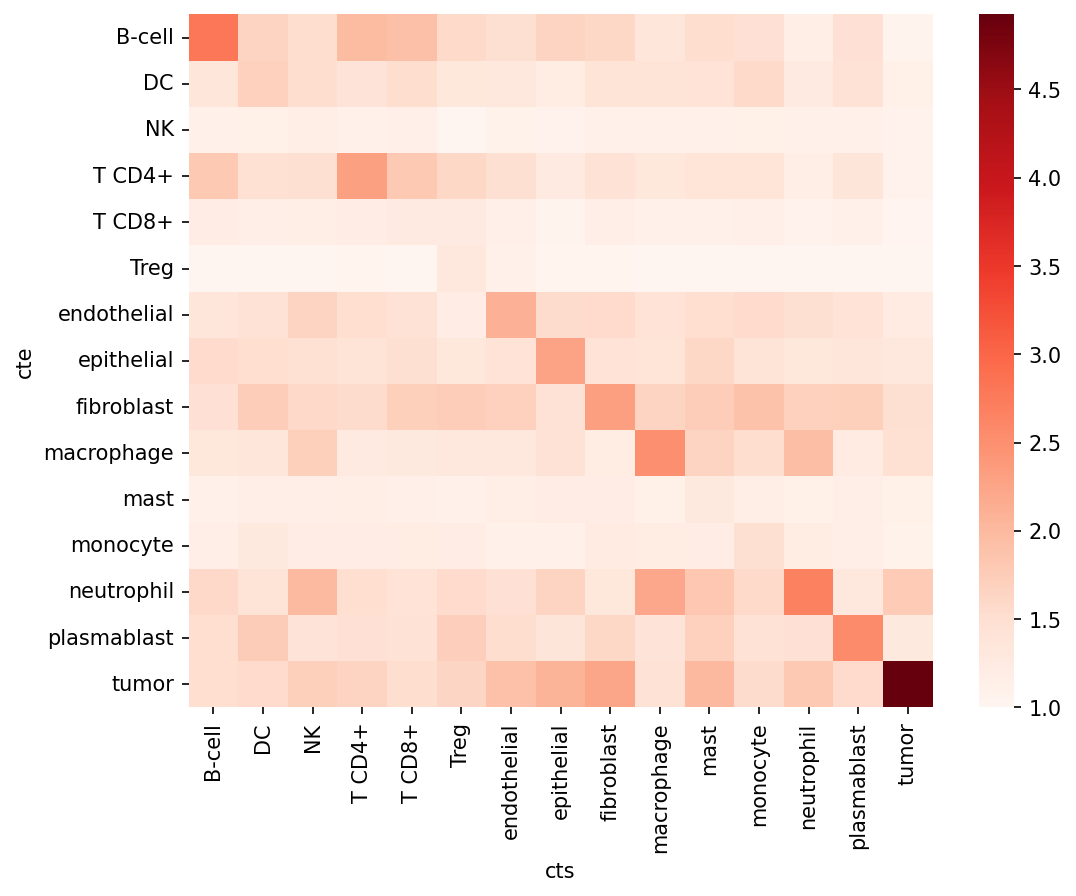

In [23]:
fig,ax = plt.subplots(figsize=(8,6),dpi=150)
sns.heatmap(cell_type_adj, annot=False, fmt=".2f", cmap="Reds", ax=ax)

In [26]:
# Example
cell_df = build_cell_df_from_st_data(
    sc_data,
    cell_type_col="cell_type",
    x_col="sampled_st_x",
    y_col="sampled_st_y",
    obsm_key="spatial",
    px_to_um=None,   # set to 0.18 if needed
)

# Optional label collapsing
cell_df["cell_type"] = cell_df["cell_type"].replace({
    "T CD4 naive": "T CD4+",
    "T CD4 memory": "T CD4+",
    "T CD8 naive": "T CD8+",
    "T CD8 memory": "T CD8+",
    "pDC": "DC",
    "mDC": "DC",
}).astype(str)

cell_df.loc[
    cell_df["cell_type"].astype(str).str.startswith("tumor"),
    "cell_type"
] = "tumor"


# ----------------------------
# 2) Compute one global cell adjacency graph
# ----------------------------
edge_kwargs = dict(
    random_shift=1e-3,
    edge_max_mad=4.0,
    n_jobs=1,
)

if cell_df["cell"].nunique() < 4:
    raise RuntimeError("Need at least 4 cells to compute adjacency.")

cell_adj_df = estimate_cell_adjacency(
    cell_df[["x", "y", "cell_type", "cell"]].copy(),
    **edge_kwargs
)

if cell_adj_df is None or len(cell_adj_df) == 0:
    raise RuntimeError("No adjacency edges computed. Check coordinates and filtering.")

# Global cell-type adjacency
cell_type_adj_sc = estimate_cell_type_adjacency(cell_adj_df)

# Ensure square + consistent ordering
all_types = sorted(cell_df["cell_type"].dropna().unique().tolist())
cell_type_adj_sc = (
    pd.DataFrame(cell_type_adj_sc)
    .reindex(index=all_types, columns=all_types)
    .fillna(0.0)
)

cell_type_adj_sc

cts,B-cell,DC,NK,T CD4+,T CD8+,Treg,endothelial,epithelial,fibroblast,macrophage,mast,monocyte,neutrophil,plasmablast,tumor
cte,,,,,,,,,,,,,,,
B-cell,3.440216,1.674603,1.587963,1.849078,1.804317,1.000000,1.735294,1.777778,1.875912,1.470280,1.449541,1.719828,1.274306,1.608059,1.466135
DC,1.441257,2.125087,1.331754,1.327855,1.429358,1.125000,1.500000,1.235294,1.550388,1.397300,1.328467,1.609412,1.394144,1.363636,1.287234
NK,1.238267,1.195745,2.128378,1.208283,1.287500,1.142857,1.307692,1.389831,1.245455,1.267470,1.190476,1.172043,1.246914,1.275862,1.234568
T CD4+,2.080898,1.903416,2.285714,3.397006,2.108730,2.447368,2.276978,1.711230,2.205543,1.638440,1.794393,1.898017,1.475375,1.878788,1.612137
T CD8+,1.433143,1.518519,1.652406,1.488515,2.320611,1.888889,1.366197,1.428571,1.453202,1.405024,1.380952,1.625616,1.342342,1.390244,1.286996
Treg,1.000000,1.125000,1.333333,1.223684,1.000000,1.565217,1.000000,1.000000,1.142857,1.125000,1.500000,1.000000,1.000000,1.000000,1.000000
endothelial,1.194332,1.137931,1.190000,1.118375,1.190184,1.000000,1.532934,1.271930,1.367021,1.182796,1.215517,1.174312,1.164062,1.205405,1.181818
epithelial,1.172775,1.153846,1.242424,1.172161,1.192661,1.000000,1.394231,1.700000,1.211009,1.223097,1.287356,1.135135,1.148438,1.208333,1.227621
fibroblast,1.238554,1.215805,1.191304,1.199749,1.166008,1.333333,1.345550,1.269231,1.686924,1.204263,1.242424,1.302857,1.152824,1.228659,1.217803


In [31]:
def rowwise_kl(K1, K2, eps=1e-8):
    K1 = np.asarray(K1)
    K2 = np.asarray(K2)

    K1 = K1 / (K1.sum(axis=1, keepdims=True) + eps)
    K2 = K2 / (K2.sum(axis=1, keepdims=True) + eps)

    kl = (K1 * (np.log(K1 + eps) - np.log(K2 + eps))).sum(axis=1)
    return kl  # per cell type

# row-wise normalize adjacency matrices to get probability distributions
cell_type_adj_norm = cell_type_adj.div(cell_type_adj.sum(axis=1) + 1e-8, axis=0)
cell_type_adj_sc_norm = cell_type_adj_sc.div(cell_type_adj_sc.sum(axis=1) + 1e-8, axis=0)
kl_per_type = rowwise_kl(cell_type_adj_norm, cell_type_adj_sc_norm)
kl_df = pd.DataFrame({
    "cell_type": cell_type_adj.index,
    "kl_divergence": kl_per_type
}).sort_values("kl_divergence", ascending=False)
kl_df

,cell_type,kl_divergence
13,plasmablast,0.013657
0,B-cell,0.012931
14,tumor,0.010002
2,NK,0.009610
9,macrophage,0.009285
5,Treg,0.008579
12,neutrophil,0.008172
10,mast,0.007279
4,T CD8+,0.006375
1,DC,0.006128


/tmp/ipykernel_2307885/2375051129.py:3: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  _ = ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')


Text(0.5, 1.0, 'KL divergence between ST and SC adjacency for each cell type')

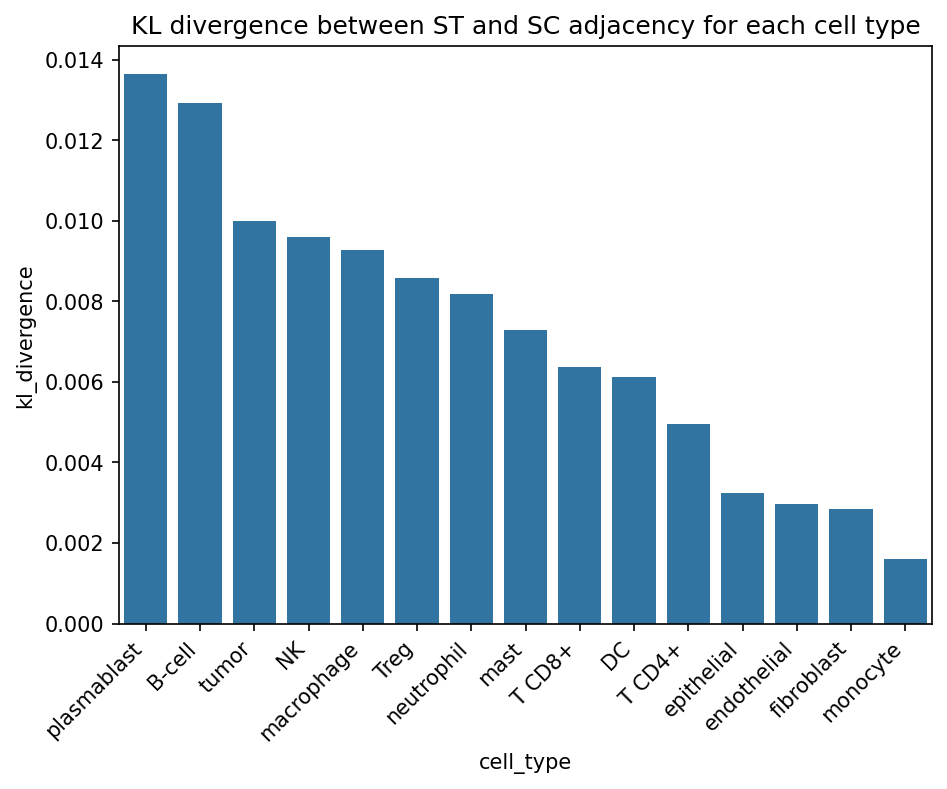

In [44]:
fig,ax = plt.subplots(figsize=(7,5),dpi=150)
sns.barplot(kl_df, x="cell_type", y="kl_divergence")
_ = ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
ax.set_title("KL divergence between ST and SC adjacency for each cell type")

Text(0.5, 0.98, 'Left: ST adjacency, Right: SC adjacency (mapped to ST coords)')

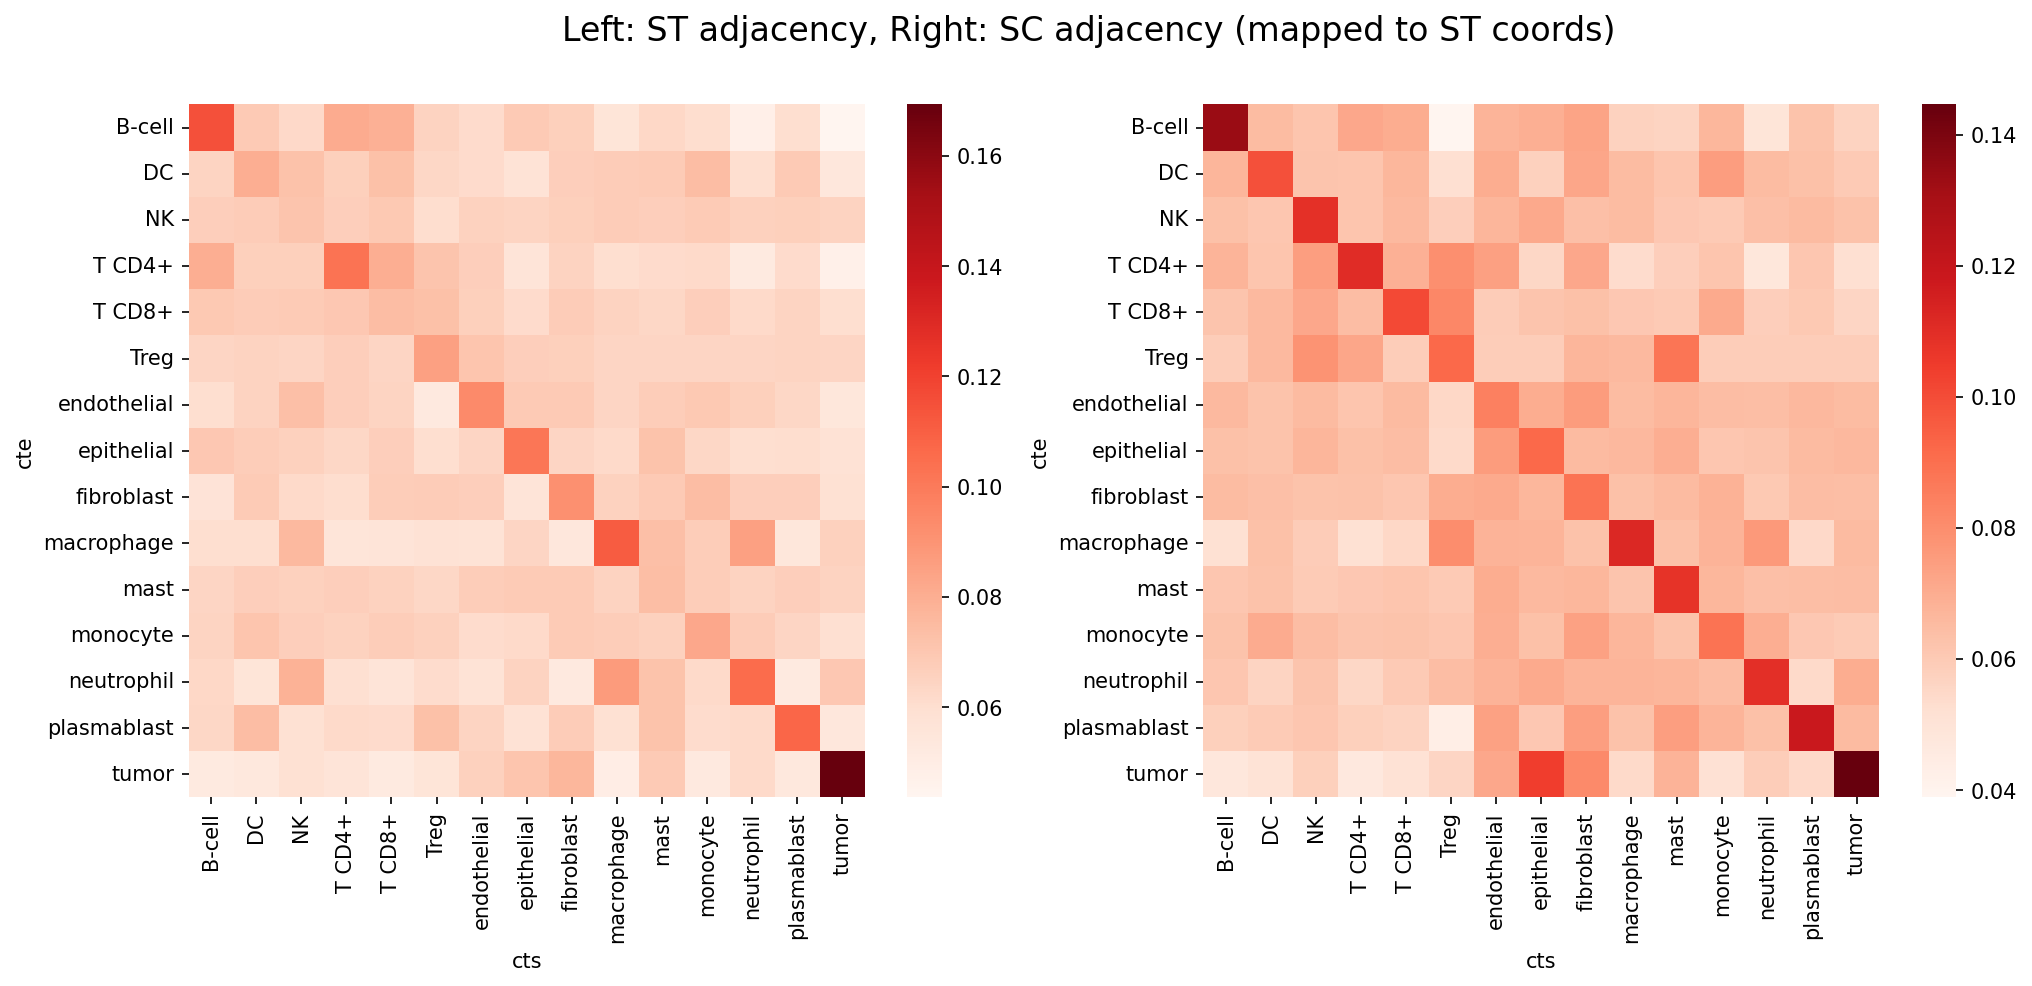

In [35]:
fig,ax = plt.subplots(ncols=2,figsize=(16,6),dpi=150)
sns.heatmap(cell_type_adj_norm, annot=False, fmt=".2f", cmap="Reds", ax=ax[0])
sns.heatmap(cell_type_adj_sc_norm, annot=False, fmt=".2f", cmap="Reds", ax=ax[1])
fig.suptitle("Left: ST adjacency, Right: SC adjacency (mapped to ST coords)", fontsize=16)

Text(0.5, 1.0, 'Absolute difference in adjacency probabilities (ST vs SC)')

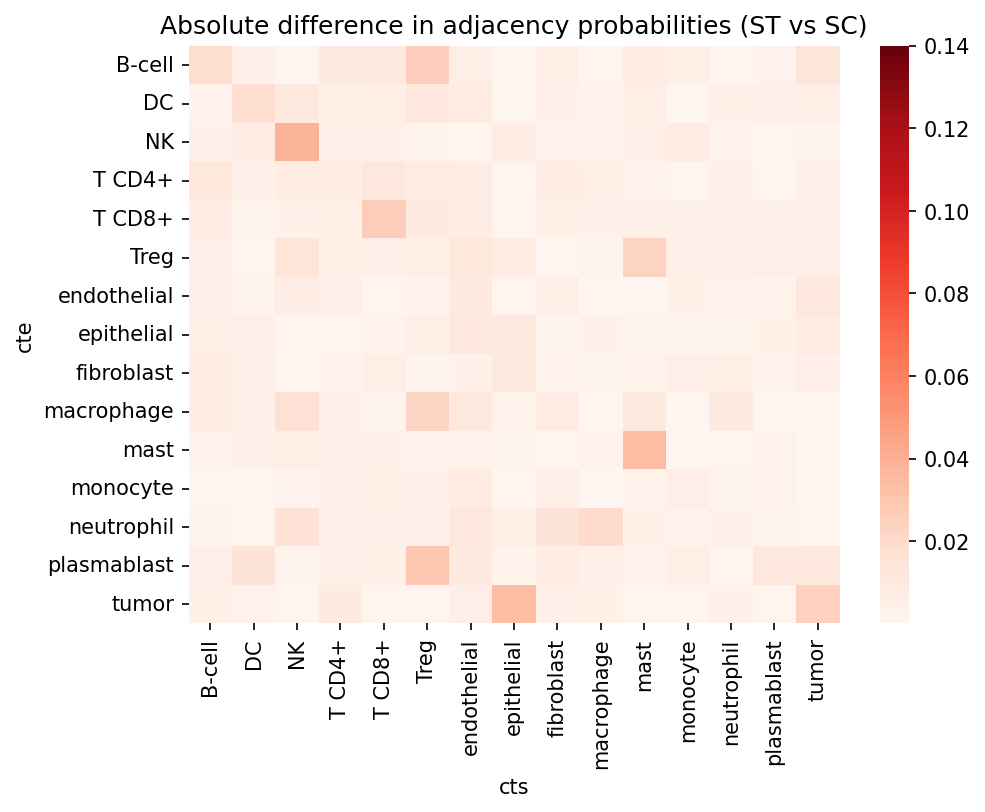

In [42]:
import numpy as np
abs_diff = cell_type_adj_norm.copy()
abs_diff.iloc[:] = np.absolute(cell_type_adj_norm.values - cell_type_adj_sc_norm.values)
    
fig,ax= plt.subplots(figsize=(7,5),dpi=150)
sns.heatmap(abs_diff, annot=False, fmt=".2f", cmap="Reds",vmax=0.14,ax=ax)
ax.set_title('Absolute difference in adjacency probabilities (ST vs SC)')


In [ ]:
import pandas as pd
import numpy as np

match_counts = sc_data.obs["st_match_1_id"].value_counts()

print("Top-1 ST coverage:", match_counts.shape[0] / st_data.n_obs)
print("Top reused ST cells:")
print(match_counts.head(20))
print()

used_any = (
    set(sc_data.obs["st_match_1_id"]) |
    set(sc_data.obs["st_match_2_id"]) |
    set(sc_data.obs["st_match_3_id"])
)
print("Top-3 union coverage:", len(used_any) / st_data.n_obs)
print()

d1 = sc_data.obs["st_match_1_dist"].to_numpy()
d2 = sc_data.obs["st_match_2_dist"].to_numpy()
d3 = sc_data.obs["st_match_3_dist"].to_numpy()

print("d2 - d1:")
print(pd.Series(d2 - d1).describe())
print()

print("d3 - d1:")
print(pd.Series(d3 - d1).describe())

In [ ]:
adata.obs.groupby('cell_type')['batch'].value_counts()